# Sentiment Analysis Project
 The goal is to analyse student feedback and determine whether students express:
- **Positive sentiment:** Satisfaction, appreciation or approval.
- **Negative sentiment:** Dissatisfaction, complaints or concerns.
- **Neutral sentiment:** Factual statements or suggestions without clear emotional polarity.

## 1.Understanding the dataset
Our Excel dataset contains 1,707 records and 20 columns.

Some of the important columns are:
Column	Description
Subject Code	Student identifier
Gender	Student gender
FacultySupportResponse	Feedback about faculty support
TASupportResponse	Feedback about teaching assistants
PeerSupportResponse	Feedback about peer support
COVID_Code	Pre-COVID or other period classification

**Our project objective:**

Analyse student feedback to understand how students feel about faculty support, teaching assistant support and peer support.

**One important distinction:** our dataset contains feedback and topic labels, but it does not contain positive, negative or neutral sentiment labels. We will therefore start with automatic sentiment scoring, then explain how to build a properly labelled machine learning model.

## 2. Import the required libraries
We import the Python libraries that will help us read, clean, analyse, classify and visualise student feedback.

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Text preprocessing
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Sentiment analysis
from nltk.sentiment import SentimentIntensityAnalyzer

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load Excel dataset
df = pd.read_excel("TopicModellingStudentFeedbackData.xlsx")

# Display first five records
df.head()

,Subject Code,Gender,US_Status,Race_Ethnicity,FacultySupportResponse,FacultySupport_Approach1_Code,FacultySupport_Approach2_Code,FacutlySupport_MultipleTopics,FacultySupport_Ambiguous,TASupportResponse,TASupport_Approach1_Code,TASupport_Approach2_Code,TASupport_MultipleTopics,TASupport_Ambiguous,PeerSupportResponse,PeerSupport_Approach1_Code,PeerSupport_Approach2_Code,PeerSupport_MultipleTopics,PeerSupport_Ambiguous,COVID_Code
0,1,Male,US Citizen,Non-Hispanic White,"Better handwriting, hard to follow lecture sli...",Teaching Practice,Teaching Practice,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PreCOVID
1,2,Male,US Citizen,Asian,Variety of office hours so that all can get he...,Interactions,Interactions,No,No,Variety of office hours so that all can get he...,TA Availability,Interactions,No,No,Communicate,Engagement,Engagement,No,No,PreCOVID
2,3,Male,US Citizen,Non-Hispanic White,"Better lecture, no more ""is that good?""",Teaching Practice,Teaching Practice,No,Yes,Respond to e-mails,Q&A,Interactions,No,No,NaN,NaN,NaN,NaN,NaN,PreCOVID
3,4,Female,US Citizen,Asian,Online resources; post more notes on line,Teaching Practice,Teaching Practice,No,No,examples,Teaching Practice,Examples and Experience,No,No,NaN,NaN,NaN,NaN,NaN,PreCOVID
4,5,Male,International,Asian,It would be better if we can have an equation ...,Examples and Experience,Teaching Practice,No,No,Let students work in groups on questions,Q&A,Interactions,No,No,NaN,NaN,NaN,NaN,NaN,PreCOVID


Check the structure:

In [4]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
df.describe(include="all")

Dataset shape: (1707, 20)

Column names:
['Subject Code', 'Gender', 'US_Status', 'Race_Ethnicity', 'FacultySupportResponse', 'FacultySupport_Approach1_Code', 'FacultySupport_Approach2_Code', 'FacutlySupport_MultipleTopics', 'FacultySupport_Ambiguous', 'TASupportResponse', 'TASupport_Approach1_Code', 'TASupport_Approach2_Code', 'TASupport_MultipleTopics', 'TASupport_Ambiguous', 'PeerSupportResponse', 'PeerSupport_Approach1_Code', 'PeerSupport_Approach2_Code', 'PeerSupport_MultipleTopics', 'PeerSupport_Ambiguous', 'COVID_Code']
<class 'pandas.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Subject Code                   1707 non-null   int64
 1   Gender                         1694 non-null   str  
 2   US_Status                      1692 non-null   str  
 3   Race_Ethnicity                 1666 non-null   str  
 4   FacultySupportRespo

,Subject Code,Gender,US_Status,Race_Ethnicity,FacultySupportResponse,FacultySupport_Approach1_Code,FacultySupport_Approach2_Code,FacutlySupport_MultipleTopics,FacultySupport_Ambiguous,TASupportResponse,TASupport_Approach1_Code,TASupport_Approach2_Code,TASupport_MultipleTopics,TASupport_Ambiguous,PeerSupportResponse,PeerSupport_Approach1_Code,PeerSupport_Approach2_Code,PeerSupport_MultipleTopics,PeerSupport_Ambiguous,COVID_Code
count,1707.000000,1694,1692,1666,1676,1675,1676,1675,1675,1592,1592,1592,1592,1592,1375,1375,1374,1374,1374,1706
unique,NaN,3,4,8,1671,3,3,2,2,1582,3,3,2,2,1345,4,4,2,2,3
top,NaN,Male,US Citizen,Asian,More office hours,Teaching Practice,Teaching Practice,No,No,Have more office hours,Teaching Practice,Interactions,No,No,Ask more questions,Questioning,Engagement,No,No,DuringCOVID
freq,NaN,1260,1322,750,3,827,873,1551,1575,3,626,870,1501,1495,14,691,551,1306,1334,789
mean,854.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,492.912771,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,427.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,854.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1280.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)
Before analysing sentiment, we need to understand our data.

A. Check missing values

In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

print(missing_values)

Subject Code                       0
Gender                            13
US_Status                         15
Race_Ethnicity                    41
FacultySupportResponse            31
FacultySupport_Approach1_Code     32
FacultySupport_Approach2_Code     31
FacutlySupport_MultipleTopics     32
FacultySupport_Ambiguous          32
TASupportResponse                115
TASupport_Approach1_Code         115
TASupport_Approach2_Code         115
TASupport_MultipleTopics         115
TASupport_Ambiguous              115
PeerSupportResponse              332
PeerSupport_Approach1_Code       332
PeerSupport_Approach2_Code       333
PeerSupport_MultipleTopics       333
PeerSupport_Ambiguous            333
COVID_Code                         1
dtype: int64


Visualise missing values:

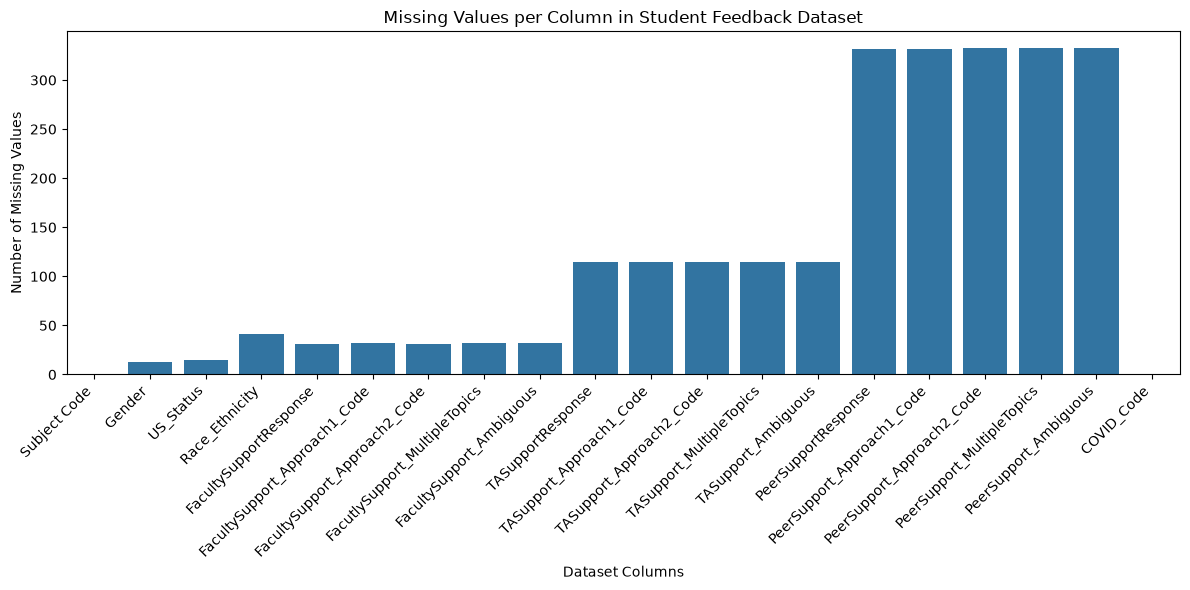

In [6]:
# Calculate missing values in each column
missing_values = df.isnull().sum()

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_values.index,
    y=missing_values.values
)

plt.title("Missing Values per Column in Student Feedback Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Explanation:**
Some students may have provided faculty feedback but left the TA or Peer support sections blank.

We need to identify these missing responses before processing the text.

B. Check duplicate records 

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


C. Select our feedback columns
We will analyse three main categories:

In [8]:
feedback_columns = [
    "FacultySupportResponse",
    "TASupportResponse",
    "PeerSupportResponse"
]

Check the available responses:

In [9]:
for column in feedback_columns:
    print("\n", column)
    print(df[column].dropna().head(5))


 FacultySupportResponse
0    Better handwriting, hard to follow lecture sli...
1    Variety of office hours so that all can get he...
2              Better lecture, no more "is that good?"
3            Online resources; post more notes on line
4    It would be better if we can have an equation ...
Name: FacultySupportResponse, dtype: str

 TASupportResponse
1    Variety of office hours so that all can get he...
2                                   Respond to e-mails
3                                             examples
4             Let students work in groups on questions
5    Use case specific examples that are useful to ...
Name: TASupportResponse, dtype: str

 PeerSupportResponse
1                                           Communicate
5     Not waste time by going around in circles with...
6                         Interact with each other more
8                                    Ask good questions
10    Each student works out 1 or 2 homework problem...
Name: PeerSupportResponse,

Why are we doing this?

We are selecting only the columns containing written feedback because sentiment analysis works with text rather than demographic identifiers such as gender or subject code.

## 4. Prepare the text dataset
We want all student responses in one column so that we can analyse them using the same NLP pipeline

In [10]:
# Convert the three feedback columns into one dataset
feedback_df = df.melt(
    id_vars=["Subject Code"],
    value_vars=feedback_columns,
    var_name="Support_Category",
    value_name="Feedback"
)

# Remove missing and empty feedback
feedback_df = feedback_df.dropna(
    subset=["Feedback"]
)

feedback_df["Feedback"] = (
    feedback_df["Feedback"].astype(str).str.strip()
)

feedback_df = feedback_df[
    feedback_df["Feedback"] != ""
]

# Reset index
feedback_df = feedback_df.reset_index(drop=True)

feedback_df.head()

,Subject Code,Support_Category,Feedback
0,1,FacultySupportResponse,"Better handwriting, hard to follow lecture sli..."
1,2,FacultySupportResponse,Variety of office hours so that all can get he...
2,3,FacultySupportResponse,"Better lecture, no more ""is that good?"""
3,4,FacultySupportResponse,Online resources; post more notes on line
4,5,FacultySupportResponse,It would be better if we can have an equation ...


Explanation of melt():

Originally, Our dataset has separate columns for faculty, TA and peer support.

The melt() function converts them into a long format.

This makes it easier to analyse all feedback using one text-processing pipeline.

## 5. Text preprocessing
This is one of the most important stages in NLP.

Computers do not naturally understand written language in the same way humans do. We therefore prepare the text before extracting features.

In [11]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("vader_lexicon")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\chris_darius\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\chris_darius\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\chris_darius\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\chris_darius\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\chris_darius\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [12]:
# B. Clean the text
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning
feedback_df["Cleaned_Feedback"] = (
    feedback_df["Feedback"].apply(clean_text)
)

feedback_df[
    ["Feedback", "Cleaned_Feedback"]
].head(10)

,Feedback,Cleaned_Feedback
0,"Better handwriting, hard to follow lecture sli...",better handwriting hard to follow lecture slid...
1,Variety of office hours so that all can get he...,variety of office hours so that all can get he...
2,"Better lecture, no more ""is that good?""",better lecture no more is that good
3,Online resources; post more notes on line,online resources post more notes on line
4,It would be better if we can have an equation ...,it would be better if we can have an equation ...
5,Be specific as to what will be asked for on th...,be specific as to what will be asked for on th...
6,Make class smaller,make class smaller
7,Make document summarizing all important equati...,make document summarizing all important equati...
8,Email class notes after every class.,email class notes after every class
9,Online resources,online resources


C. Tokenisation

Tokenisation means breaking a sentence into individual words or tokens.

In [13]:
feedback_df["Tokens"] = (
    feedback_df["Cleaned_Feedback"].apply(word_tokenize)
)

feedback_df[["Cleaned_Feedback", "Tokens"]].head()

,Cleaned_Feedback,Tokens
0,better handwriting hard to follow lecture slid...,"[better, handwriting, hard, to, follow, lectur..."
1,variety of office hours so that all can get he...,"[variety, of, office, hours, so, that, all, ca..."
2,better lecture no more is that good,"[better, lecture, no, more, is, that, good]"
3,online resources post more notes on line,"[online, resources, post, more, notes, on, line]"
4,it would be better if we can have an equation ...,"[it, would, be, better, if, we, can, have, an,..."


D. Stopword 

Stopwords are common words that often carry limited information for text analysis.

In [14]:
stop_words = set(stopwords.words("english"))

# Preserve negation words
stop_words = stop_words - {
    "not", "no", "nor", "never"
}

def remove_stopwords(tokens):

    return [
        word for word in tokens
        if word not in stop_words
    ]


feedback_df["Processed_Tokens"] = (
    feedback_df["Tokens"].apply(remove_stopwords)
)

feedback_df["Processed_Text"] = (
    feedback_df["Processed_Tokens"].apply(
        lambda tokens: " ".join(tokens)
    )
)

feedback_df[
    ["Feedback", "Processed_Text"]
].head()

,Feedback,Processed_Text
0,"Better handwriting, hard to follow lecture sli...",better handwriting hard follow lecture slides ...
1,Variety of office hours so that all can get he...,variety office hours get help needed
2,"Better lecture, no more ""is that good?""",better lecture no good
3,Online resources; post more notes on line,online resources post notes line
4,It would be better if we can have an equation ...,would better equation sheet


For the next stage, we will use the original feedback rather than aggressively cleaned text. This is because punctuation, capitalisation and negation can influence sentiment scores.

## 6. Perform sentiment analysis using VADER

It is a rule-based sentiment analysis tool in NLTK. It uses a sentiment dictionary and linguistic rules to estimate the emotional polarity of text.

It does not require us to train a model first.

**A. Initialise the sentiment analyser.**

In [15]:
# Create sentiment analyser
sia = SentimentIntensityAnalyzer()

**B. Calculate sentiment scores.**

In [16]:
# Calculate sentiment scores
feedback_df["Sentiment_Scores"] = (
    feedback_df["Feedback"].apply(
        lambda text: sia.polarity_scores(str(text))
    )
)

feedback_df.head()

,Subject Code,Support_Category,Feedback,Cleaned_Feedback,Tokens,Processed_Tokens,Processed_Text,Sentiment_Scores
0,1,FacultySupportResponse,"Better handwriting, hard to follow lecture sli...",better handwriting hard to follow lecture slid...,"[better, handwriting, hard, to, follow, lectur...","[better, handwriting, hard, follow, lecture, s...",better handwriting hard follow lecture slides ...,"{'neg': 0.124, 'neu': 0.619, 'pos': 0.257, 'co..."
1,2,FacultySupportResponse,Variety of office hours so that all can get he...,variety of office hours so that all can get he...,"[variety, of, office, hours, so, that, all, ca...","[variety, office, hours, get, help, needed]",variety office hours get help needed,"{'neg': 0.0, 'neu': 0.803, 'pos': 0.197, 'comp..."
2,3,FacultySupportResponse,"Better lecture, no more ""is that good?""",better lecture no more is that good,"[better, lecture, no, more, is, that, good]","[better, lecture, no, good]",better lecture no good,"{'neg': 0.218, 'neu': 0.495, 'pos': 0.287, 'co..."
3,4,FacultySupportResponse,Online resources; post more notes on line,online resources post more notes on line,"[online, resources, post, more, notes, on, line]","[online, resources, post, notes, line]",online resources post notes line,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound..."
4,5,FacultySupportResponse,It would be better if we can have an equation ...,it would be better if we can have an equation ...,"[it, would, be, better, if, we, can, have, an,...","[would, better, equation, sheet]",would better equation sheet,"{'neg': 0.0, 'neu': 0.775, 'pos': 0.225, 'comp..."


VADER produces four scores:
Score	Meaning
Positive	Positive sentiment strength
Negative	Negative sentiment strength
Neutral	Neutral sentiment strength
Compound	Overall normalised sentiment score

The compound score ranges from -1 to +1.
- Close to +1 = More positive.
- Close to -1 = More negative.
- Close to 0 = More neutral.

**C. Extract the compound score.**

We need the compound score to classify the feedback.

In [17]:
feedback_df["Compound_Score"] = (
    feedback_df["Sentiment_Scores"].apply(
        lambda score: score["compound"]
    )
)

feedback_df[
    ["Feedback", "Compound_Score"]
].head(10)

,Feedback,Compound_Score
0,"Better handwriting, hard to follow lecture sli...",0.3612
1,Variety of office hours so that all can get he...,0.4019
2,"Better lecture, no more ""is that good?""",0.1779
3,Online resources; post more notes on line,0.0000
4,It would be better if we can have an equation ...,0.4404
5,Be specific as to what will be asked for on th...,0.0000
6,Make class smaller,0.0000
7,Make document summarizing all important equati...,0.2023
8,Email class notes after every class.,0.0000
9,Online resources,0.0000


D. Classify sentiment
We will use VADER's standard compound thresholds:
- Compound score >= 0.05: Positive.
- Compound score = 0.05:
  return "Positive"
  
  elif score <= -0.05:
  return "Negative"
  
  else:
  return "Neutral"
feedback_df["Sentiment"] = (
feedback_df["Compound_Score"].apply(
classify_sentiment
)
)

feedback_df[
[
"Feedback",
"Compound_Score",
"Sentiment"
]
].head(20)


**What have we achieved?**

We have transformed unstructured student feedback into structured sentiment categories.

For example:

| Feedback | Possible interpretation |
|---|---|
| I really appreciate the support | Positive |
| The lectures are very confusing | Negative |
| Classes take place every Monday | Neutral |

Remember that VADER is a general-purpose English sentiment tool. A sentence such as "Provide more examples" may be a constructive suggestion rather than an expression of negative emotion. Its classification should be reviewed against human-labelled feedback.

### . Analyse sentiment results

Now that we have sentiment labels, let's understand what the results tell us.

### A. Count positive, negative and neutral responses

```python
sentiment_counts = feedback_df["Sentiment"].value_counts()

print(sentiment_counts)

In [28]:
sentiment_counts = feedback_df["Sentiment"].value_counts()

print(sentiment_counts)

Sentiment
Positive    2480
Neutral     1463
Negative     700
Name: count, dtype: int64


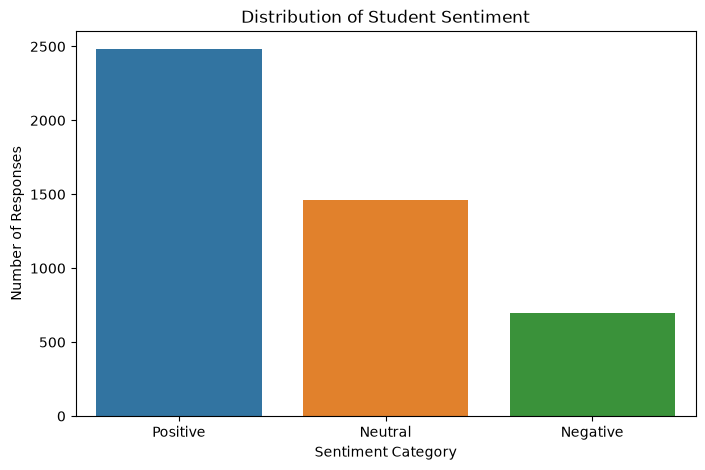

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=feedback_df,
    x="Sentiment",
    hue="Sentiment"
)

plt.title("Distribution of Student Sentiment")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Responses")

plt.show()

Explanation:

This graph shows how many student responses fall into each sentiment category.

For example, if negative feedback is higher, it may indicate areas where students are experiencing challenges.

Do not assume that every suggestion is negative feedback. Review the actual comments before drawing conclusions.

B. Calculate sentiment percentages

In [30]:
sentiment_percentage = (
    feedback_df["Sentiment"]
    .value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

Sentiment
Positive    53.41
Neutral     31.51
Negative    15.08
Name: proportion, dtype: float64


This gives us the percentage of positive, negative and neutral responses.

C. Compare sentiment by support category
This is particularly useful for your dataset.

We want to understand whether students have different experiences with:
- Faculty support.
- Teaching assistant support.
- Peer support.

In [31]:
category_sentiment = pd.crosstab(
    feedback_df["Support_Category"],
    feedback_df["Sentiment"]
)

print(category_sentiment)

Sentiment               Negative  Neutral  Positive
Support_Category                                   
FacultySupportResponse       237      480       959
PeerSupportResponse          236      474       665
TASupportResponse            227      509       856


Visualisation:

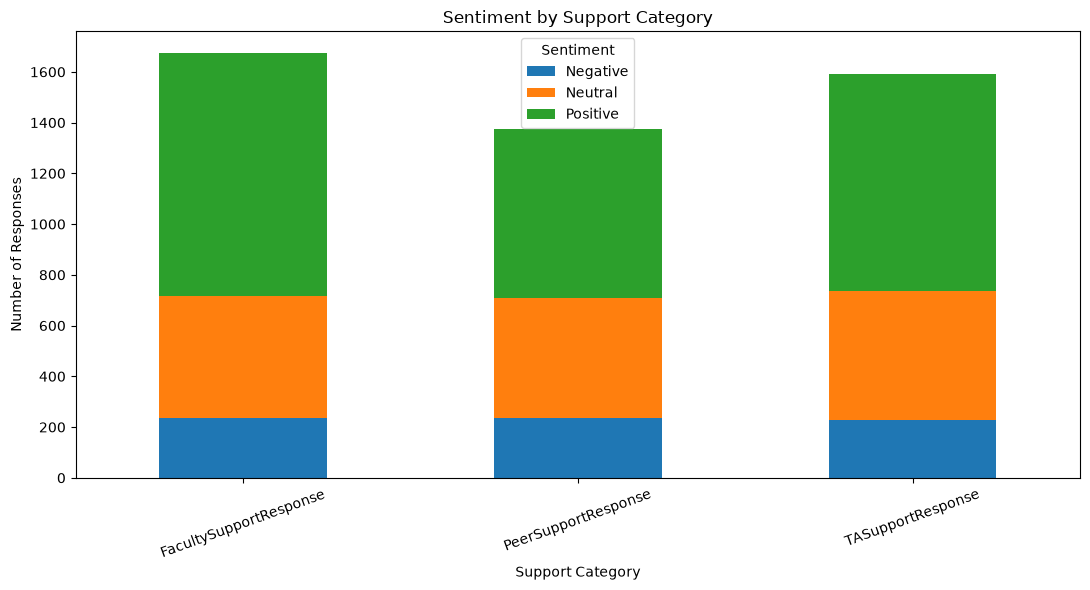

In [32]:
category_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Sentiment by Support Category")
plt.xlabel("Support Category")
plt.ylabel("Number of Responses")

plt.xticks(rotation=20)
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()

Interpretation:

This graph helps us compare the distribution of sentiment across the three support categories.

For example:
- Are students more positive about faculty support?
- Are there more negative comments about TA support?
- How do students describe peer support?
These are questions we can investigate using the results.

D. Display positive and negative comments

In [33]:
positive_feedback = feedback_df[
    feedback_df["Sentiment"] == "Positive"
]

negative_feedback = feedback_df[
    feedback_df["Sentiment"] == "Negative"
]

print("POSITIVE FEEDBACK")
display(positive_feedback[["Feedback", "Compound_Score"]].head(10))

print("NEGATIVE FEEDBACK")
display(negative_feedback[["Feedback", "Compound_Score"]].head(10))

POSITIVE FEEDBACK


,Feedback,Compound_Score
0,"Better handwriting, hard to follow lecture sli...",0.3612
1,Variety of office hours so that all can get he...,0.4019
2,"Better lecture, no more ""is that good?""",0.1779
4,It would be better if we can have an equation ...,0.4404
7,Make document summarizing all important equati...,0.2023
10,Take the time to explain concepts more in dept...,0.4215
11,Choose the same learning management system. La...,0.4939
13,Taking every opportunity possible to connect i...,0.4215
15,"Keep lectures fresh and interesting, not just ...",0.8074
16,Teach well,0.2732


NEGATIVE FEEDBACK


,Feedback,Compound_Score
12,"More on line files, lecture notes, and more pr...",-0.4522
19,Provide extensive feedback on papers and homew...,-0.2500
51,Give examples in class that are unique and not...,-0.5209
53,Be attentive to students in class to see if th...,-0.4404
56,Postponed midterm after snow day.,-0.2023
61,The most important to me is clear and detailed...,-0.1932
64,Uploading the Notes and Lecture Materials onli...,-0.4019
75,Cover examples closer to homework or the exam ...,-0.4019
82,Go through a tough problem,-0.4939
86,In class problems,-0.4019


This step is important because numerical results alone do not tell us why students feel a particular way.

### Build a machine learning sentiment classifier
So far, we have used VADER, which is a rule-based sentiment analyser.

Now let's understand how to build a machine learning model that learns from labelled student feedback.

We will use:
- TF-IDF for feature extraction.
- Logistic Regression for classification.
- Train-test split for model evaluation.
Important: Our Excel file does not have human-verified sentiment labels. Therefore, we must manually label a sample of feedback before training a genuine supervised model.

A. Prepare data for manual labelling
First, export the feedback for annotation.

In [35]:
# Select feedback that needs human labelling
annotation_data = feedback_df[
    ["Feedback", "Support_Category"]
].copy()

# Create an empty label column
annotation_data["Human_Sentiment"] = ""

# Export for manual labelling
annotation_data.to_excel(
    "Student_Feedback_For_Labelling.xlsx",
    index=False
)

Open the exported Excel file and assign one of these labels to each response:

Label	Meaning
Positive	Clear satisfaction or appreciation
Negative	Clear dissatisfaction or complaint
Neutral	Factual or emotion-free statement

For example:

Feedback	Human_Sentiment
The lecturer explains concepts very well	Positive
The lecturer does not respond to questions	Negative
Classes are held every Monday	Neutral
More examples should be provided	Neutral

The last example is neutral because a request for improvement does not automatically mean the student is expressing negative emotion.

For reliable results, have ambiguous responses reviewed by a second annotator where possible.

B. Load the labelled dataset

After manually labelling and saving the Excel file:

In [36]:
labelled_df = pd.read_excel(
    "Student_Feedback_For_Labelling.xlsx"
)

# Remove records without labels
labelled_df = labelled_df.dropna(
    subset=["Human_Sentiment"]
)

labelled_df["Human_Sentiment"] = (
    labelled_df["Human_Sentiment"].str.strip().str.title()
)

# Keep only valid sentiment classes
valid_labels = ["Positive", "Negative", "Neutral"]

labelled_df = labelled_df[
    labelled_df["Human_Sentiment"].isin(valid_labels)
]

print(labelled_df["Human_Sentiment"].value_counts())

Human_Sentiment
Neutral     2
Positive    1
Negative    1
Name: count, dtype: int64


C. Define features and target
In machine learning:
- X (Features): The text we use to make predictions.
- y (Target): The sentiment category we want to predict.

In [37]:
X = labelled_df["Feedback"]

y = labelled_df["Human_Sentiment"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (4,)
Target: (4,)


We are teaching the model to identify patterns in written feedback that correspond to the three sentiment categories.

D. Split the dataset

We divide our labelled dataset into training and testing sets.

In [40]:
# Count sentiment categories
sentiment_counts = feedback_df["Sentiment"].value_counts()

# Keep categories with at least 2 records
valid_classes = sentiment_counts[
    sentiment_counts >= 2
].index

feedback_df = feedback_df[
    feedback_df["Sentiment"].isin(valid_classes)
]

X = feedback_df["Feedback"]
y = feedback_df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Explanation:
Dataset	Purpose
80% Training	Used to teach the model
20% Testing	Used to evaluate the model

random_state=42 makes the split reproducible.

stratify=y attempts to preserve the class proportions in both sets. It requires enough examples in every class.

E. Convert text into numerical features using TF-IDF
Computers cannot directly train traditional machine learning algorithms on sentences.


TF-IDF stands for Term Frequency–Inverse Document Frequency.


It converts text into numerical representations based on how important words are within a document compared with the whole collection.

In [41]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

# Learn vocabulary and transform training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (3714, 5000)
Testing shape: (929, 5000)


Why use ngram_range=(1, 2)?


It captures:
- Unigrams: individual words, e.g. good, poor.
- Bigrams: pairs of words, e.g. very good, not helpful.
This can help the model understand short phrases.


Notice that we use fit_transform() on training data and only transform() on testing data. This prevents information from the test set leaking into training.

F. Train the Logistic Regression model

In [42]:
# Initialise model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


Explanation:


Logistic Regression learns relationships between the TF-IDF features and the sentiment labels.


For a new sentence, it estimates the probability of belonging to each sentiment category and selects the most likely class.


class_weight="balanced" helps account for unequal numbers of examples across sentiment classes.

G. Make predictions

In [43]:
# Predict sentiments on test data
y_pred = model.predict(X_test_tfidf)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(results.head(15))

,Actual,Predicted
0,Positive,Positive
1,Positive,Positive
2,Negative,Negative
3,Positive,Neutral
4,Positive,Positive
5,Neutral,Neutral
6,Positive,Negative
7,Positive,Neutral
8,Neutral,Neutral
9,Positive,Positive


Now we can compare what the model predicted against the human-assigned labels.

# Evaluate the machine learning model
This stage tells us how well our classifier performs on unseen test data.

A. Accuracy

In [44]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 77.83 %


Accuracy measures the percentage of correctly classified feedback.


For example, an accuracy of 85% means that 85 out of every 100 test predictions were correct.

B. Precision, recall and F1-score

In [45]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative       0.56      0.72      0.63       140
     Neutral       0.75      0.82      0.78       293
    Positive       0.89      0.77      0.83       496

    accuracy                           0.78       929
   macro avg       0.73      0.77      0.75       929
weighted avg       0.80      0.78      0.78       929



Understanding the metrics:

Metric	Explanation
Precision	How many predictions for a class were correct?
Recall	How many actual examples of a class did the model identify?
F1-score	Balance between precision and recall
Support	Number of actual test examples in each class


C. Confusion matrix

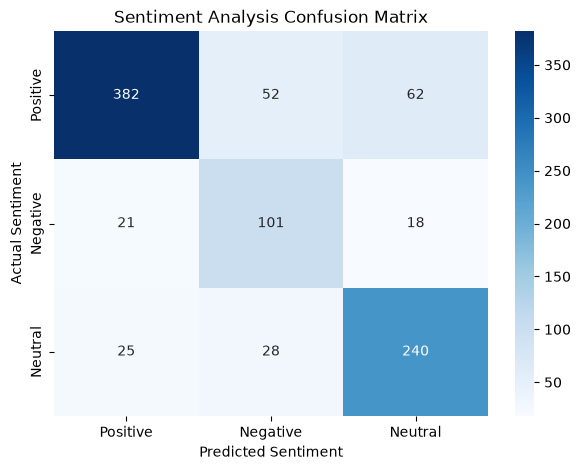

In [46]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Positive", "Negative", "Neutral"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Positive", "Negative", "Neutral"],
    yticklabels=["Positive", "Negative", "Neutral"]
)

plt.title("Sentiment Analysis Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

How to interpret it:

- Diagonal values represent correct predictions.
- Values outside the diagonal represent incorrect predictions.

For example, if the model predicts Negative when the actual sentiment is Positive, that is a misclassification.

### Test the model with new student feedback
Once the model is trained, we can give it new feedback that it has never seen before.

In [47]:
new_feedback = [
    "The lecturer explains concepts very well",
    "The teaching assistant is not helpful",
    "Classes take place every Monday",
    "I really appreciate the support"
]

# Convert new text into TF-IDF features
new_feedback_tfidf = tfidf.transform(new_feedback)

# Predict sentiment
predictions = model.predict(new_feedback_tfidf)

# Display results
for text, sentiment in zip(new_feedback, predictions):

    print("Feedback:", text)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Feedback: The lecturer explains concepts very well
Predicted Sentiment: Neutral
--------------------------------------------------
Feedback: The teaching assistant is not helpful
Predicted Sentiment: Positive
--------------------------------------------------
Feedback: Classes take place every Monday
Predicted Sentiment: Neutral
--------------------------------------------------
Feedback: I really appreciate the support
Predicted Sentiment: Positive
--------------------------------------------------


What is happening?
1. We provide new student comments.
2. TF-IDF converts them into numerical features.
3. The trained Logistic Regression model analyses the features.
4. The model predicts Positive, Negative or Neutral.
Predict sentiment with probabilities
We can also see how confident the model is in each class.

In [48]:
probabilities = model.predict_proba(new_feedback_tfidf)

probability_results = pd.DataFrame(
    probabilities,
    columns=model.classes_
)

display(probability_results)

,Negative,Neutral,Positive
0,0.163115,0.454679,0.382206
1,0.006641,0.014927,0.978431
2,0.185079,0.414332,0.400589
3,0.035126,0.064735,0.900139


For example, a prediction might have:

Sentiment	Probability
Positive	0.80
Negative	0.10
Neutral	0.10


This means the model estimates an 80% probability of positive sentiment.


These probabilities are model estimates, not guarantees of correctness.

# Save the final results
We can export the sentiment analysis results into Excel for further reporting.

In [49]:
# Save feedback and sentiment results
feedback_df.to_excel(
    "Student_Sentiment_Analysis_Results.xlsx",
    index=False
)

print("Sentiment results exported successfully!")

Sentiment results exported successfully!


You can also save the trained model and TF-IDF vectorizer for future use

In [50]:
import joblib

joblib.dump(model, "sentiment_model.pkl")

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved!")

Model and vectorizer saved!


# Conclusion
The Student Feedback Sentiment Analysis demonstrates how Natural Language Processing (NLP) and Machine Learning can be used to analyse unstructured student feedback and extract meaningful insights.

Using the student feedback dataset, we developed a text-processing pipeline involving data cleaning, tokenisation, stopword removal and sentiment classification.

VADER was used to perform initial rule-based sentiment analysis, categorising student feedback into positive, negative and neutral sentiments. We also explored a supervised machine learning approach using TF-IDF for feature extraction and Logistic Regression for sentiment classification.

These provides an opportunity to understand students' perceptions of faculty support, teaching assistant support and peer support.

By analysing sentiment distributions and evaluating the classification model, educational institutions can identify areas of satisfaction, recognise challenges and make informed decisions to improve the student learning experience.

Overall, this demonstrates how data science can transform unstructured textual feedback into actionable information for decision-making.
### Next Steps and Recommendations
The following activities will help improve and make it more useful.
No.	Next Step	Expected Outcome
1	Improve data labelling	Obtain reliable sentiment labels through human annotation

2	Handle class imbalance	Improve classification across all sentiment categories

3	Compare ML algorithms	Compare Logistic Regression, Naive Bayes and SVM

4	Improve text preprocessing	Apply lemmatization and preserve important contextual words

5	Perform model evaluation	Compare accuracy, precision, recall and F1-score

6	Apply advanced NLP	Explore BERT and other transformer models

7	Develop a dashboard	Present sentiment trends through interactive visualisations

8	Generate recommendations	Identify areas requiring improvements in student support